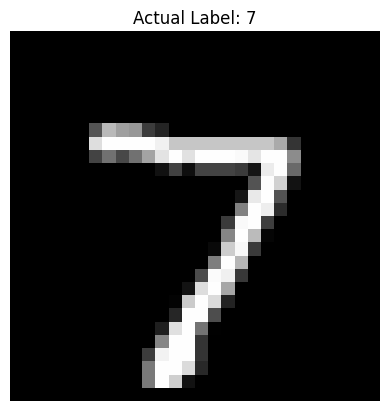

Predicted Class: 7


In [ ]:
# =============================================================================
# 📘 AI for Developers – Code Examples for Learning
#
# Welcome to the code examples shared under the AI for Developers initiative!
# These examples are designed to help you explore, experiment, and accelerate
# your journey in building intelligent, agent-based systems and AI-integrated
# workflows.
#
# Whether you're working with LangChain, Semantic Kernel, or custom AI agents,
# the goal is to provide practical blueprints that go beyond prompting and into
# programming real AI workflows.
# Refer : https://python.langchain.com/docs/introduction/
# -----------------------------------------------------------------------------
# ⚠️ Disclaimer & Brand Usage Note
#
# These examples are provided for educational purposes only.
# - Please review and test thoroughly before using in production.
# - Do not redistribute under the name "AI for Developers" without permission.
# - You are welcome to learn, remix, and extend — just keep attribution and 
#   brand safety in mind.
#
# The "AI for Developers" brand stands for community, trust, and ethical innovation.
# Help us keep it that way by using this content responsibly.
#
# -----------------------------------------------------------------------------
# 🔗 Join the movement: https://www.linkedin.com/groups/14276631/
#     Github repository : https://github.com/ai4developers/codewithai/
# Stay curious, build boldly.
# — AI for Developers Team
# =============================================================================



import torch
import torch.nn as nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# ✅ Define the same model architecture
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# ✅ Instantiate the model
model = MLP()

# ✅ Load the saved weights
model.load_state_dict(torch.load("mnist_mlp_cpu.pth"))
model.eval()

# ✅ Prepare MNIST test dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_dataset = datasets.MNIST(root="./data", train=False, transform=transform, download=True)

# ✅ Pick an example (e.g., the first image)
image, label = test_dataset[0]

# ✅ Show the image
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual Label: {label}")
plt.axis("off")
plt.show()

# ✅ Run inference
with torch.no_grad():
    output = model(image.unsqueeze(0))
    predicted_class = torch.argmax(output, dim=1).item()

print(f"Predicted Class: {predicted_class}")